### Que2.-
#### In this dataset you have to predict that whether we have to give ATTORNEY to the clients or not (0=Yes, 1=No) based on below factors.
#### CLMAGE - Age of Client
#### CLMSEX - Sex of client (0=Male, 1= Female)
#### SEATBELT - Whether client has Seatbelt or not (0=Yes, 1=No)
#### CLMINSUR - Whether Client give Insurance or not (0=Yes, 1=No)
#### LOSS - Loss that client faced

#### Prepare model by using logistic regression & Also calculate Accuracy by confusion matrix, Calculate accuracy score, precision score, recall score, f1 score.

#### Dataset : Claimants.csv

In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("Claimants.csv")

In [4]:
df.head()

,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,0,0.0,1.0,0.0,50.0,34.940
1,1,1.0,0.0,0.0,18.0,0.891
2,1,0.0,1.0,0.0,5.0,0.330
3,0,0.0,1.0,1.0,31.0,0.037
4,1,0.0,1.0,0.0,30.0,0.038


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1340 entries, 0 to 1339
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   ATTORNEY  1340 non-null   int64  
 1   CLMSEX    1328 non-null   float64
 2   CLMINSUR  1299 non-null   float64
 3   SEATBELT  1292 non-null   float64
 4   CLMAGE    1151 non-null   float64
 5   LOSS      1340 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 62.9 KB


In [6]:
df.shape

(1340, 6)

In [7]:
df.isna().sum()

ATTORNEY      0
CLMSEX       12
CLMINSUR     41
SEATBELT     48
CLMAGE      189
LOSS          0
dtype: int64

In [8]:
df['CLMAGE'] = df['CLMAGE'].fillna(df['CLMAGE'].mean())

In [9]:
df['CLMAGE'].isnull().sum()

0

In [10]:
df['CLMSEX'] = df['CLMSEX'].fillna(df['CLMSEX'].mode()[0])
df['CLMINSUR'] = df['CLMINSUR'].fillna(df['CLMINSUR'].mode()[0])
df['SEATBELT'] = df['SEATBELT'].fillna(df['SEATBELT'].mode()[0])

In [11]:
df.isna().sum()

ATTORNEY    0
CLMSEX      0
CLMINSUR    0
SEATBELT    0
CLMAGE      0
LOSS        0
dtype: int64

In [12]:
df.corr()

,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
ATTORNEY,1.000000,0.076564,0.076631,-0.055848,0.009886,-0.219715
CLMSEX,0.076564,1.000000,0.065976,-0.016327,-0.022444,-0.028412
CLMINSUR,0.076631,0.065976,1.000000,0.019953,0.044706,0.004641
SEATBELT,-0.055848,-0.016327,0.019953,1.000000,-0.025379,0.111879
CLMAGE,0.009886,-0.022444,0.044706,-0.025379,1.000000,0.057641
LOSS,-0.219715,-0.028412,0.004641,0.111879,0.057641,1.000000


<Axes: >

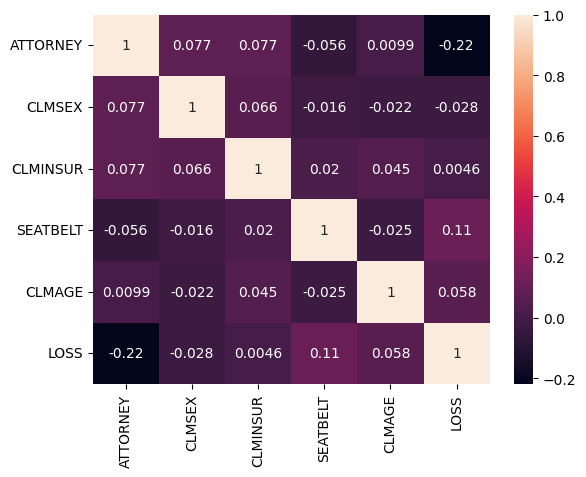

In [13]:
sns.heatmap(df.corr(),annot = True)

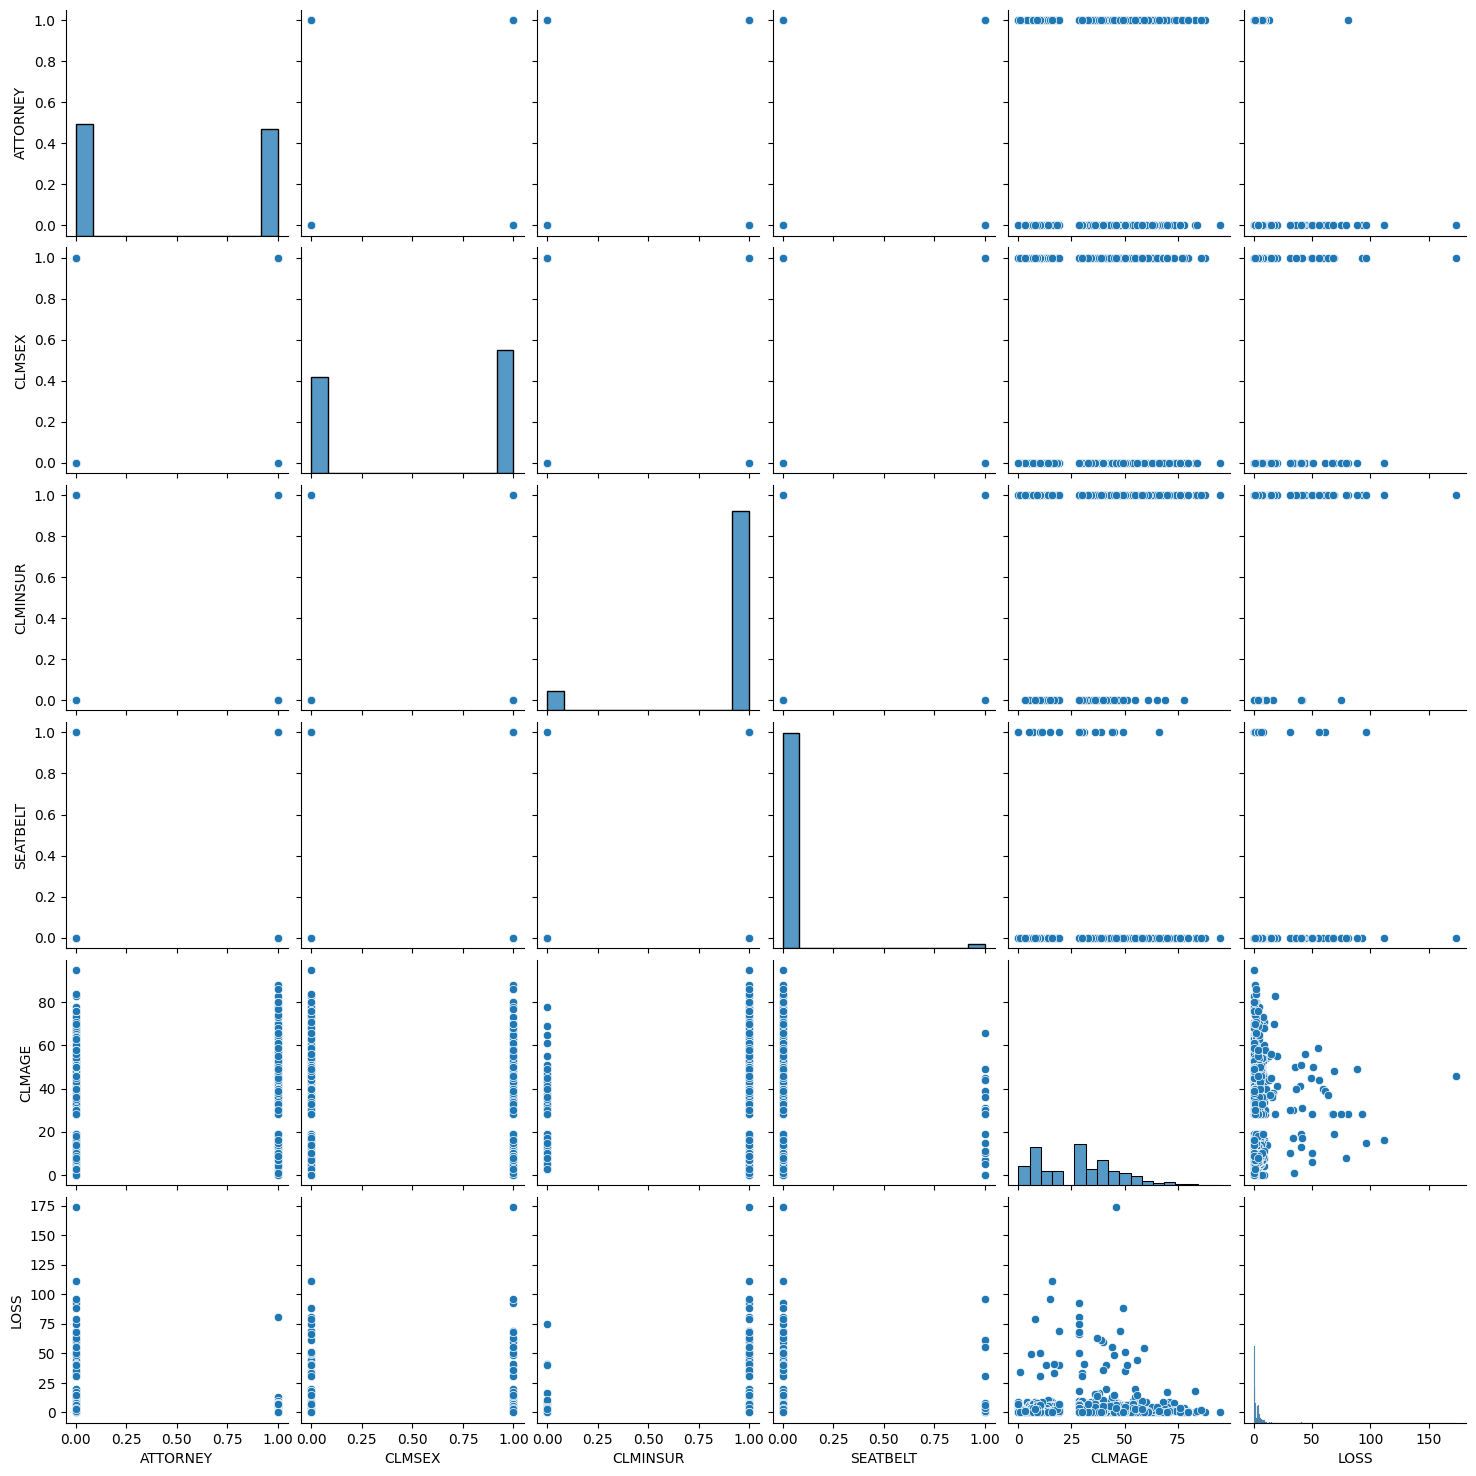

In [14]:
sns.pairplot(df)

In [15]:
X = df.drop('ATTORNEY',axis = 1)
y = df['ATTORNEY']

In [16]:
df['ATTORNEY'].value_counts()

ATTORNEY
0    685
1    655
Name: count, dtype: int64

In [18]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,train_size=0.7,random_state=42)

In [19]:
from sklearn.linear_model import LogisticRegressionCV
model =  LogisticRegressionCV()
model.fit(X_train,y_train)

LogisticRegressionCV()

In [20]:
y_pred = model.predict(X_test)
# model.predict_proba(y_pred)

In [21]:
model.predict_proba(X_test)


array([[7.95386642e-01, 2.04613358e-01],
       [8.74355821e-01, 1.25644179e-01],
       [3.03161800e-01, 6.96838200e-01],
       [3.81959237e-01, 6.18040763e-01],
       [7.77656101e-01, 2.22343899e-01],
       [6.51645613e-01, 3.48354387e-01],
       [3.96170916e-01, 6.03829084e-01],
       [4.63286754e-01, 5.36713246e-01],
       [4.41835702e-01, 5.58164298e-01],
       [8.79929318e-01, 1.20070682e-01],
       [3.48746863e-01, 6.51253137e-01],
       [3.23102763e-01, 6.76897237e-01],
       [4.07016112e-01, 5.92983888e-01],
       [4.53151676e-01, 5.46848324e-01],
       [3.28107061e-01, 6.71892939e-01],
       [7.36414078e-01, 2.63585922e-01],
       [3.30558058e-01, 6.69441942e-01],
       [2.67377696e-01, 7.32622304e-01],
       [3.52296445e-01, 6.47703555e-01],
       [9.14211680e-01, 8.57883201e-02],
       [1.00000000e+00, 1.09787845e-12],
       [7.10987619e-01, 2.89012381e-01],
       [7.58999473e-01, 2.41000527e-01],
       [5.01328762e-01, 4.98671238e-01],
       [8.081107

In [22]:
from sklearn.metrics import confusion_matrix

matrix = confusion_matrix(y_test,y_pred)
matrix

array([[135,  67],
       [ 41, 160]], dtype=int64)

In [23]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score
from sklearn.metrics import recall_score

accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)

In [24]:
from sklearn.metrics import classification_report

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.77      0.67      0.71       202
           1       0.70      0.80      0.75       201

    accuracy                           0.73       403
   macro avg       0.74      0.73      0.73       403
weighted avg       0.74      0.73      0.73       403



In [25]:
print(f"Accuracy = {accuracy*100:.2f}%")
print(f"Precision = {precision*100:.2f}%")
print(f"F1-score= {f1*100:.2f}%")
print(f"recall= {recall*100:.2f}%")

Accuracy = 73.20%
Precision = 70.48%
F1-score= 74.77%
recall= 79.60%
